# 01: Review sentiment analysis

**Owner:** Leonardo (Market Intelligence & Visualization Analyst) · **Ticket:** #6

Scores each review's text for sentiment, validates it against reviewer scores, and aggregates it per anime.

**Method (agreed on #6):** VADER, scored **sentence by sentence** and averaged per review. Scoring a whole review at once saturates near +1 (see #6), so it can't tell reviews apart. The scoring code lives in `src/capstone/sentiment.py` so `build-dataset` can reuse it.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from capstone.dataset import SENTIMENT_CACHE, load_anime, load_reviews
from capstone.sentiment import POSITIVE_CUTOFF, SENTIMENT_COLUMNS, _analyzer, cached_review_sentiment, split_sentences

sns.set_theme(style="whitegrid")

In [2]:
reviews = load_reviews()
anime = load_anime()
print(f"{len(reviews):,} reviews, {len(anime):,} anime")
reviews.head()

130,517 reviews, 16,216 anime


,uid,profile,anime_uid,text,score,link,story_score,animation_score,sound_score,character_score,enjoyment_score
0,255938,DesolatePsyche,34096,"First things first. My ""reviews"" system is exp...",8,https://myanimelist.net/reviews.php?id=255938,8,8,10,9,8
1,259117,baekbeans,34599,Let me start off by saying that Made in Abyss ...,10,https://myanimelist.net/reviews.php?id=259117,10,10,10,10,10
2,253664,skrn,28891,"Art 9/10: It is great, especially the actions ...",7,https://myanimelist.net/reviews.php?id=253664,7,9,8,8,8
3,8254,edgewalker00,2904,Story taking place 1 yr from where season 1 tr...,9,https://myanimelist.net/reviews.php?id=8254,9,9,10,10,9
4,291149,aManOfCulture99,4181,Kyoto Animations greatest strength is being ab...,10,https://myanimelist.net/reviews.php?id=291149,10,8,9,10,10


## 1. Look at the text first

Before scoring, check what VADER will actually read: boilerplate, line breaks, very short reviews, and the score distribution.

Line breaks in text: 0.0% of reviews
Reviews under 5 words: 0


Median length: 345 words, 20 sentences


Mention 'spoiler': 14.7%


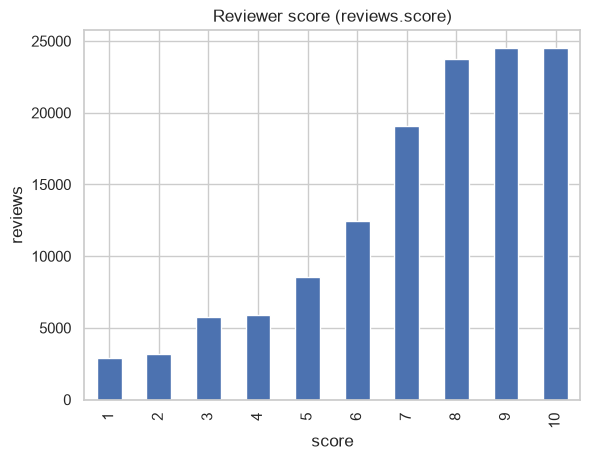

In [3]:
words = reviews["text"].str.split().str.len()
print(f"Line breaks in text: {reviews['text'].str.contains(chr(10)).mean():.1%} of reviews")
print(f"Reviews under 5 words: {(words < 5).sum()}")
print(f"Median length: {words.median():.0f} words, {reviews['text'].map(lambda t: len(split_sentences(t))).median():.0f} sentences")
print(f"Mention 'spoiler': {reviews['text'].str.contains('spoiler', case=False).mean():.1%}")
reviews["score"].value_counts().sort_index().plot.bar(title="Reviewer score (reviews.score)", xlabel="score", ylabel="reviews");

Findings:
- Cleaning (#4) already removed the page boilerplate, and no review is empty.
- There are **no line breaks**, so sentences are split on `.`, `!` and `?`.
- Some reviews use headers like "Story 7/10 … Art 10/10". VADER ignores the numbers, so they don't move the score.
- Scores lean high: most reviews are 7–10. Expect most reviews to read as positive.

## 2. Score every review (sentence-level VADER)

About 1.6% of reviews barely use punctuation, so a single "sentence" can be the whole review, which saturates just like whole-review scoring. `split_sentences()` therefore cuts any run longer than 40 words (`MAX_SENTENCE_WORDS`) into 40-word pieces. Section 6d checks this fix.

Scoring takes about 5 minutes, so `cached_review_sentiment()` saves the scores in `data/processed/review_sentiment_v1.parquet` and only rescores reviews that are new or whose text changed. `build-dataset` uses the same cache. After changing how a review is scored, bump `SCORING_VERSION` in `src/capstone/sentiment.py` to start a fresh cache.

In [4]:
scored = cached_review_sentiment(reviews, SENTIMENT_CACHE)
reviews = reviews.merge(scored[["uid", "sentiment"]], on="uid", how="left")
reviews["sentiment"].describe()

count    130517.000000
mean          0.194764
std           0.183187
min          -0.993517
25%           0.078540
50%           0.192760
75%           0.308831
max           0.990400
Name: sentiment, dtype: float64

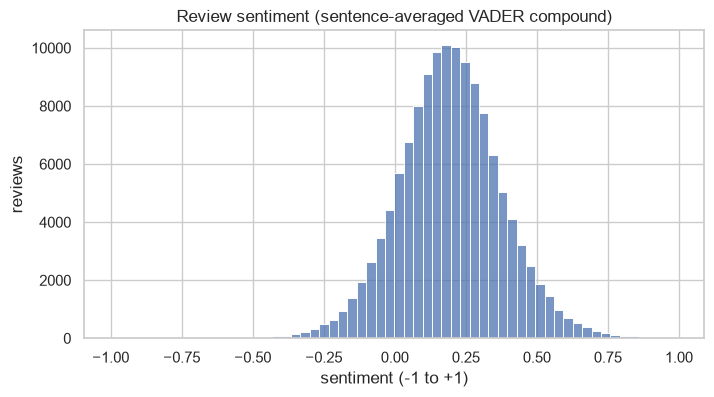

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(reviews["sentiment"], bins=60, ax=ax)
ax.set(title="Review sentiment (sentence-averaged VADER compound)", xlabel="sentiment (-1 to +1)", ylabel="reviews");

## 3. Tune the "positive" cutoff

VADER's default rule calls a text positive at compound ≥ 0.05. That rule was designed for short social-media posts. Here we check it against what reviewers actually rated:

- **Clearly positive reviews:** `reviews.score` ≥ 7
- **Clearly negative reviews:** `reviews.score` ≤ 4
- Scores 5–6 are mixed, so they're left out of the tuning.

For each candidate cutoff we measure how many positive reviews it calls positive and how many negative reviews it wrongly calls positive. The best cutoff maximizes **balanced accuracy**: the average of "% of positive reviews caught" and "% of negative reviews correctly rejected". Balanced accuracy is used because positive reviews outnumber negative ones about 4 to 1, and plain accuracy would favor calling everything positive.

In [6]:
labeled = reviews[(reviews["score"] >= 7) | (reviews["score"] <= 4)]
is_high = labeled["score"] >= 7
print(f"{len(labeled):,} labeled reviews: {is_high.sum():,} rated 7+, {(~is_high).sum():,} rated 4 or lower")

rows = []
for cutoff in np.round(np.arange(-0.10, 0.41, 0.01), 2):
    called_pos = labeled["sentiment"] >= cutoff
    caught = called_pos[is_high].mean()          # rated 7+ and called positive
    false_pos = called_pos[~is_high].mean()      # rated 4 or lower but called positive
    rows.append({"cutoff": cutoff, "high_called_positive": caught, "low_called_positive": false_pos,
                 "balanced_accuracy": (caught + (1 - false_pos)) / 2,
                 "all_reviews_positive": (reviews["sentiment"] >= cutoff).mean()})
tuning = pd.DataFrame(rows)
best = tuning.loc[tuning["balanced_accuracy"].idxmax()]
print(f"Best cutoff: {best['cutoff']:.2f}")
tuning[tuning["cutoff"].isin([0.05, best["cutoff"]])].round(3)

109,523 labeled reviews: 91,852 rated 7+, 17,671 rated 4 or lower
Best cutoff: 0.12


,cutoff,high_called_positive,low_called_positive,balanced_accuracy,all_reviews_positive
15,0.05,0.903,0.381,0.761,0.798
22,0.12,0.799,0.196,0.801,0.667


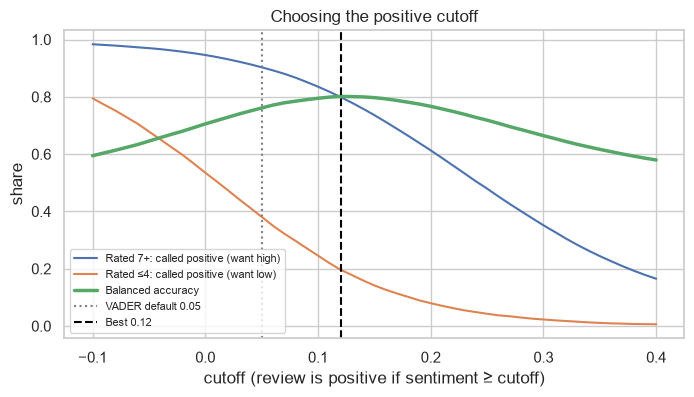

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(tuning["cutoff"], tuning["high_called_positive"], label="Rated 7+: called positive (want high)")
ax.plot(tuning["cutoff"], tuning["low_called_positive"], label="Rated ≤4: called positive (want low)")
ax.plot(tuning["cutoff"], tuning["balanced_accuracy"], label="Balanced accuracy", linewidth=2.5)
ax.axvline(0.05, color="grey", linestyle=":", label="VADER default 0.05")
ax.axvline(best["cutoff"], color="black", linestyle="--", label=f"Best {best['cutoff']:.2f}")
ax.set(title="Choosing the positive cutoff", xlabel="cutoff (review is positive if sentiment ≥ cutoff)", ylabel="share")
ax.legend(fontsize=8);

**Choice: a review is positive when sentiment ≥ 0.12** (`POSITIVE_CUTOFF` in `src/capstone/sentiment.py`). Compared with VADER's default 0.05, it cuts low-rated reviews wrongly called positive from 38% to 20%, while still catching 80% of reviews rated 7+. The best cutoff is stable: 0.11–0.14 give practically the same balanced accuracy, and defining "high" and "low" as 8+ vs ≤5 instead moves it only to 0.14.

## 4. Aggregate to one row per anime

`build-dataset` adds four columns per anime with `add_sentiment()`, so they are already in `load_anime()`:

| Column | Meaning |
|---|---|
| `mean_review_sentiment` | Average sentiment of the anime's reviews |
| `positive_review_share` | Share of its reviews with sentiment ≥ 0.12 |
| `adjusted_review_sentiment` | The mean blended with 5 imaginary reviews at the catalog average |
| `adjusted_positive_share` | The share blended the same way |

The adjusted versions use the same method as `adjusted_review_score` (#5): `(n × value + 5 × catalog value) / (n + 5)`. An anime with 1 review moves most of the way to the catalog average, while one with 20 reviews barely moves. **Anime with no reviews stay blank (NaN).** "No reviews" is not the same as "neutral reviews".

In [8]:
has_reviews = anime["n_reviews"] > 0
print(f"Anime with reviews: {has_reviews.sum():,}  |  without: {(~has_reviews).sum():,}")
print("Blank sentiment among anime WITHOUT reviews:", anime.loc[~has_reviews, SENTIMENT_COLUMNS].isna().all(axis=1).mean())
print("Filled sentiment among anime WITH reviews:  ", anime.loc[has_reviews, SENTIMENT_COLUMNS].notna().all(axis=1).mean())
anime[SENTIMENT_COLUMNS].describe().round(3)

Anime with reviews: 8,113  |  without: 8,103
Blank sentiment among anime WITHOUT reviews: 1.0
Filled sentiment among anime WITH reviews:   1.0


,mean_review_sentiment,adjusted_review_sentiment,positive_review_share,adjusted_positive_share
count,8113.000,8113.000,8113.000,8113.000
mean,0.188,0.193,0.642,0.660
std,0.138,0.053,0.346,0.128
min,-0.725,-0.083,0.000,0.139
25%,0.107,0.162,0.450,0.556
50%,0.190,0.193,0.700,0.693
75%,0.271,0.224,1.000,0.753
max,0.943,0.426,1.000,0.971


### What the adjustment does

Raw values for anime with only 1–2 reviews spread all the way out (a single review gives a share of exactly 0% or 100%). The adjusted values pull those in toward the catalog average, while titles with many reviews keep their own value.

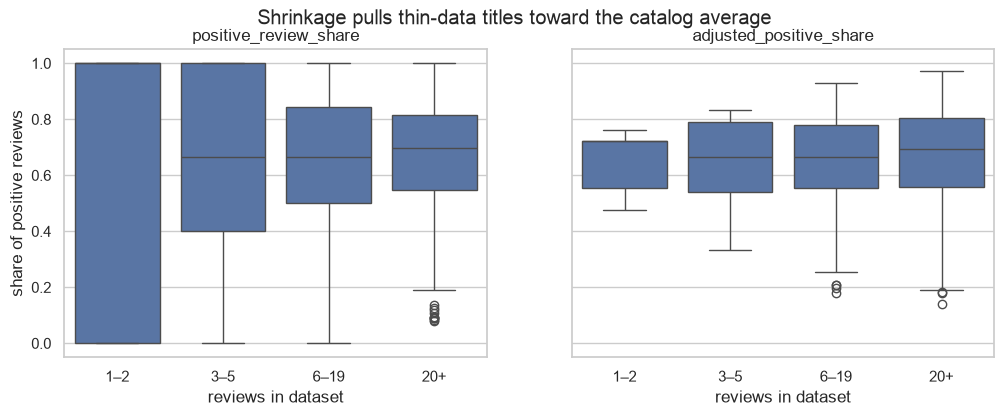

In [9]:
reviewed = anime[has_reviews].copy()
reviewed["review_count"] = pd.cut(reviewed["n_reviews"], [0, 2, 5, 19, np.inf], labels=["1–2", "3–5", "6–19", "20+"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, col in zip(axes, ["positive_review_share", "adjusted_positive_share"]):
    sns.boxplot(data=reviewed, x="review_count", y=col, ax=ax)
    ax.set(title=col, xlabel="reviews in dataset", ylabel="share of positive reviews")
fig.suptitle("Shrinkage pulls thin-data titles toward the catalog average");

In [10]:
# Example: the most extreme raw values come from titles with one or two reviews
cols = ["title", "n_reviews", "mean_review_sentiment", "adjusted_review_sentiment", "positive_review_share", "adjusted_positive_share"]
pd.concat([
    reviewed.nlargest(5, "mean_review_sentiment")[cols],
    reviewed[reviewed["n_reviews"] >= 20].nlargest(5, "mean_review_sentiment")[cols],
], keys=["Top raw mean (any count)", "Top raw mean (20+ reviews)"]).round(3)

title  \
Top raw mean (any count)   4978                          Mini Moni Yaru no da Pyon!   
                           4363   Tengen Toppa Gurren Lagann Movie Zenyasai: Vir...   
                           3778                                      Papa to Odorou   
                           2600   Pokemon Fushigi no Dungeon: Shutsudou Pokemon ...   
                           2439        Doraemon Movie 05: Nobita no Makai Daibouken   
Top raw mean (20+ reviews) 4627                                 Yume-iro Pâtissière   
                           7370                                            Love Lab   
                           6565                                     Kimi to Boku. 2   
                           9692                                    Ore Monogatari!!   
                           12542                                         Yuru Camp△   

                                  n_reviews  mean_review_sentiment  \
Top raw mean (any count)   4978           1                  0.943   
                           4363           1                  0.915   
                           3778           1                  0.893   
                           2600           1                  0.872   
                           2439           1                  0.811   
Top raw mean (20+ reviews) 4627          29                  0.466   
                           7370          29                  0.389   
                           6565          20                  0.385   
                           9692          94                  0.385   
                           12542        122                  0.383   

                                  adjusted_review_sentiment  \
Top raw mean (any count)   4978                       0.319   
                           4363                       0.315   
                           3778                       0.311   
                           2600                       0.308   
                           2439                       0.297   
Top raw mean (20+ reviews) 4627                       0.426   
                           7370                       0.360   
                           6565                       0.347   
                           9692                       0.375   
                           12542                      0.376   

                                  positive_review_share  \
Top raw mean (any count)   4978                   1.000   
                           4363                   1.000   
                           3778                   1.000   
                           2600                   1.000   
                           2439                   1.000   
Top raw mean (20+ reviews) 4627                   0.966   
                           7370                   1.000   
                           6565                   0.950   
                           9692                   0.936   
                           12542                  0.984   

                                  adjusted_positive_share  
Top raw mean (any count)   4978                     0.722  
                           4363                     0.722  
                           3778                     0.722  
                           2600                     0.722  
                           2439                     0.722  
Top raw mean (20+ reviews) 4627                     0.922  
                           7370                     0.951  
                           6565                     0.893  
                           9692                     0.923  
                           12542                    0.971

In [11]:
# Highest adjusted sentiment: what would feed the ranking
anime.nlargest(10, "adjusted_review_sentiment")[cols + ["score", "members"]].round(3)

,title,n_reviews,mean_review_sentiment,adjusted_review_sentiment,positive_review_share,adjusted_positive_share,score,members
4627,Yume-iro Pâtissière,29,0.466,0.426,0.966,0.922,7.99,53217
10421,Wakaba*Girl,8,0.492,0.378,1.000,0.872,6.96,33399
12542,Yuru Camp△,122,0.383,0.376,0.984,0.971,8.31,209936
12417,Natsume Yuujinchou Roku,17,0.429,0.376,1.000,0.924,8.68,101995
9692,Ore Monogatari!!,94,0.385,0.375,0.936,0.923,8.03,373132
11056,"Kono Danshi, Mahou ga Oshigoto Desu.",7,0.497,0.371,1.000,0.861,7.13,18369
14032,Anima Yell!,11,0.451,0.371,1.000,0.896,7.06,25601
1839,Lovely★Complex,176,0.375,0.370,0.909,0.902,8.13,356826
14031,Aikatsu Friends!,4,0.578,0.365,1.000,0.815,7.53,6809
4246,Kobato.,60,0.377,0.363,0.917,0.897,8.03,123252


## 5. Sanity check: does sentiment agree with the scores?

If VADER measures opinion, reviews with higher scores should read more positively. We check two levels, because `score` means different things in the two tables:

- **Review level:** each review's sentiment vs. **`reviews.score`**, the rating that reviewer gave (plus their sub-scores).
- **Anime level:** each anime's aggregated sentiment vs. **`anime.score`**, MyAnimeList's overall rating from all users (most of whom wrote no review), and vs. the anime's average review scores.

**Pearson** measures a straight-line relationship between the values. **Spearman** compares only rankings, so it is less affected by extreme values. Both run from −1 to +1. As a rough guide, 0.1 is weak, 0.3 moderate, and 0.5+ strong.

**Headline measure: Spearman.** Review scores are whole numbers from 1 to 10 and sentiment is skewed, so a rank-based correlation fits better than Pearson. Pearson is shown next to it for reference. Every number quoted in the data dictionary and the write-up comes from the **Headline numbers** cell at the end of this section.

### 5a. Review level

In [12]:
score_cols = ["score", "story_score", "animation_score", "sound_score", "character_score", "enjoyment_score"]
review_corr = pd.DataFrame({
    "pearson": [reviews["sentiment"].corr(reviews[c]) for c in score_cols],
    "spearman": [reviews["sentiment"].corr(reviews[c], method="spearman") for c in score_cols],
}, index=[f"reviews.{c}" for c in score_cols]).round(3)
review_corr

,pearson,spearman
reviews.score,0.506,0.486
reviews.story_score,0.444,0.425
reviews.animation_score,0.369,0.346
reviews.sound_score,0.380,0.357
reviews.character_score,0.489,0.468
reviews.enjoyment_score,0.502,0.480


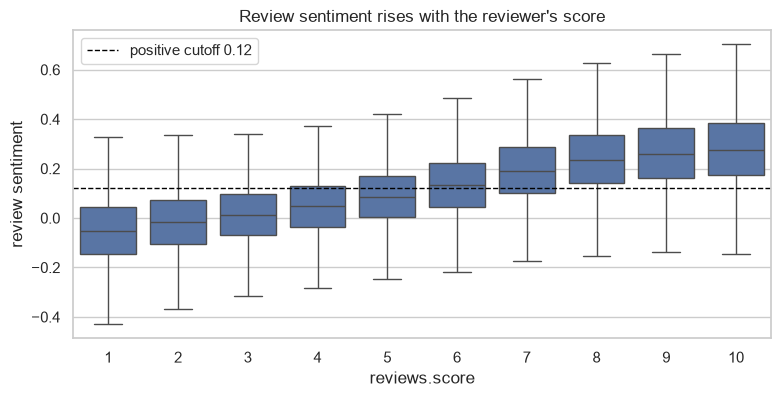

In [13]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(data=reviews, x="score", y="sentiment", showfliers=False, ax=ax)
ax.axhline(POSITIVE_CUTOFF, color="black", linestyle="--", linewidth=1, label=f"positive cutoff {POSITIVE_CUTOFF}")
ax.set(title="Review sentiment rises with the reviewer's score", xlabel="reviews.score", ylabel="review sentiment")
ax.legend();

### 5b. Anime level

In [14]:
sent_cols = ["mean_review_sentiment", "adjusted_review_sentiment", "positive_review_share", "adjusted_positive_share"]
targets = ["score", "mean_review_score", "mean_story_score", "mean_animation_score",
           "mean_sound_score", "mean_character_score", "mean_enjoyment_score"]

def corr_table(df, method):
    return pd.DataFrame({t: [df[s].corr(df[t], method=method) for s in sent_cols] for t in targets}, index=sent_cols).round(3)

reviewed = anime[anime["n_reviews"] > 0]
print(f"All {len(reviewed):,} reviewed anime, Spearman:")
display(corr_table(reviewed, "spearman"))
well = anime[anime["n_reviews"] >= 10]
print(f"{len(well):,} anime with 10+ reviews, Spearman:")
display(corr_table(well, "spearman"))
print("Pearson, all reviewed anime:")
corr_table(reviewed, "pearson")

All 8,113 reviewed anime, Spearman:


,score,mean_review_score,mean_story_score,mean_animation_score,mean_sound_score,mean_character_score,mean_enjoyment_score
mean_review_sentiment,0.339,0.542,0.451,0.422,0.428,0.518,0.537
adjusted_review_sentiment,0.345,0.534,0.447,0.403,0.415,0.518,0.531
positive_review_share,0.227,0.460,0.388,0.342,0.356,0.446,0.464
adjusted_positive_share,0.348,0.503,0.427,0.376,0.398,0.493,0.502


2,266 anime with 10+ reviews, Spearman:


,score,mean_review_score,mean_story_score,mean_animation_score,mean_sound_score,mean_character_score,mean_enjoyment_score
mean_review_sentiment,0.396,0.609,0.494,0.414,0.447,0.622,0.639
adjusted_review_sentiment,0.400,0.611,0.497,0.414,0.445,0.624,0.641
positive_review_share,0.406,0.619,0.512,0.424,0.462,0.630,0.647
adjusted_positive_share,0.417,0.623,0.517,0.428,0.464,0.634,0.651


Pearson, all reviewed anime:


,score,mean_review_score,mean_story_score,mean_animation_score,mean_sound_score,mean_character_score,mean_enjoyment_score
mean_review_sentiment,0.328,0.537,0.445,0.436,0.433,0.508,0.534
adjusted_review_sentiment,0.350,0.494,0.418,0.380,0.388,0.482,0.491
positive_review_share,0.313,0.498,0.414,0.402,0.411,0.470,0.494
adjusted_positive_share,0.348,0.480,0.409,0.365,0.381,0.470,0.476


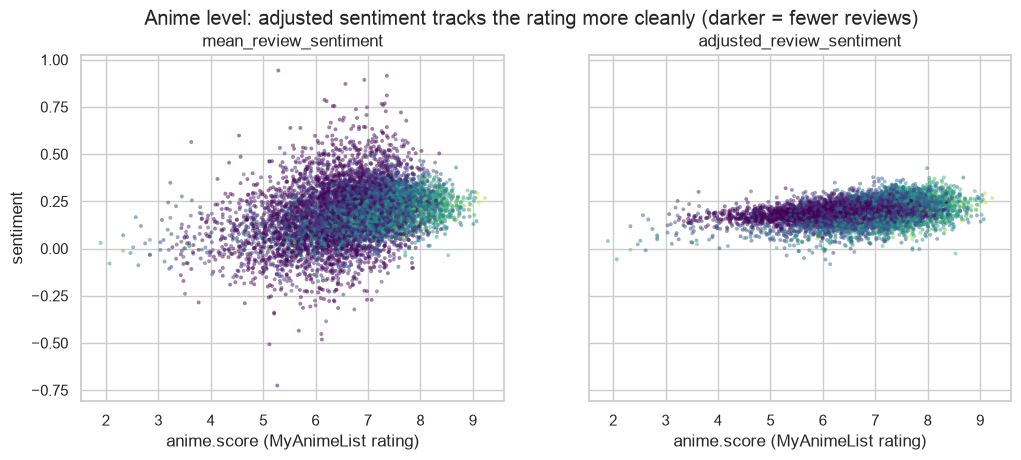

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, col in zip(axes, ["mean_review_sentiment", "adjusted_review_sentiment"]):
    sns.scatterplot(data=reviewed, x="score", y=col, hue=np.log10(reviewed["n_reviews"]), palette="viridis",
                    s=8, alpha=0.5, linewidth=0, ax=ax, legend=False)
    ax.set(title=col, xlabel="anime.score (MyAnimeList rating)", ylabel="sentiment")
fig.suptitle("Anime level: adjusted sentiment tracks the rating more cleanly (darker = fewer reviews)");

### 5c. Does sentiment also measure the show's *tone*?

The highest adjusted sentiment went mostly to gentle, cheerful shows (section 4). VADER scores words, so a glowing review of a dark thriller ("the villain's brutal killings were terrifying") may still read as negative. To test this, we compare sentiment by genre **among reviews that gave a 9 or 10**. If sentiment measured only opinion, these reviews should all score about the same.

In [16]:
genres = [c for c in anime.columns if c.startswith("genre_") and c != "genre_count"]
with_genres = reviews.merge(anime[["uid", *genres]], left_on="anime_uid", right_on="uid", suffixes=("", "_anime"))
rows = []
for g in genres:
    d = with_genres[with_genres[g]]
    if len(d) >= 2000:
        rows.append({"genre": g.removeprefix("genre_"), "reviews": len(d),
                     "mean_review_score": d["score"].mean(), "share_rated_9_10": (d["score"] >= 9).mean(),
                     "median_sentiment_9_10": d.loc[d["score"] >= 9, "sentiment"].median()})
by_genre = pd.DataFrame(rows).set_index("genre").sort_values("median_sentiment_9_10")
top = with_genres[with_genres["score"] >= 9]
print(f"Median sentiment of all 9–10 reviews: {top['sentiment'].median():.3f}")
print(f"Across genres, Spearman(mean review score, sentiment of 9–10 reviews) = "
      f"{by_genre['mean_review_score'].corr(by_genre['median_sentiment_9_10'], method='spearman'):.2f}")
pd.concat([by_genre.head(6), by_genre.tail(6)]).round(3)

Median sentiment of all 9–10 reviews: 0.267
Across genres, Spearman(mean review score, sentiment of 9–10 reviews) = -0.00


,reviews,mean_review_score,share_rated_9_10,median_sentiment_9_10
genre,,,,
dementia,2952,7.072,0.407,0.158
horror,9226,6.832,0.320,0.183
police,2968,7.878,0.485,0.184
psychological,13538,7.561,0.451,0.191
thriller,7706,8.087,0.546,0.203
mecha,9579,7.275,0.369,0.223
romance,40065,7.366,0.381,0.294
school,31614,7.361,0.372,0.299
harem,9509,6.535,0.227,0.300


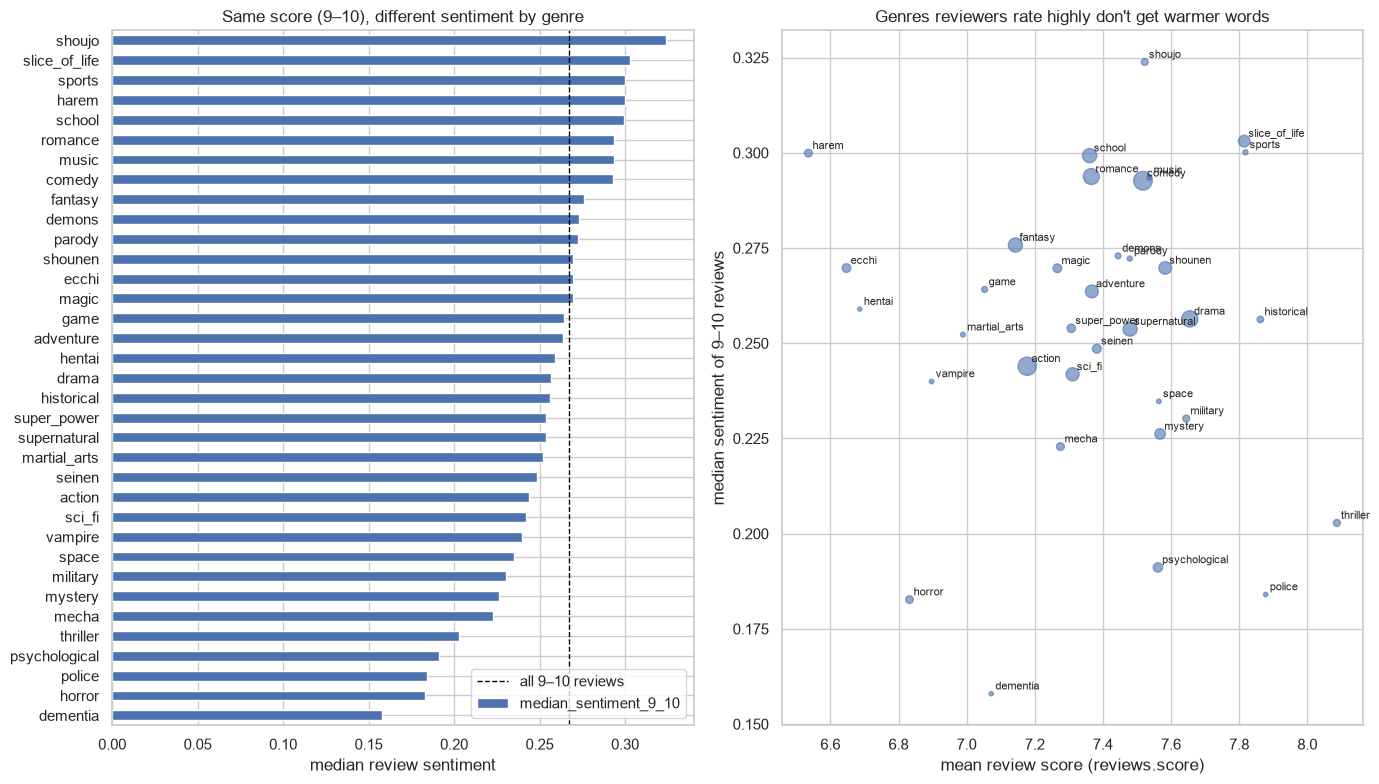

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 8))
by_genre["median_sentiment_9_10"].plot.barh(ax=axes[0])
axes[0].axvline(top["sentiment"].median(), color="black", linestyle="--", linewidth=1, label="all 9–10 reviews")
axes[0].set(title="Same score (9–10), different sentiment by genre", xlabel="median review sentiment", ylabel="")
axes[0].legend()

axes[1].scatter(by_genre["mean_review_score"], by_genre["median_sentiment_9_10"], s=by_genre["reviews"] / 300, alpha=0.6)
for g, row in by_genre.iterrows():
    axes[1].annotate(g, (row["mean_review_score"], row["median_sentiment_9_10"]), fontsize=8, xytext=(3, 3), textcoords="offset points")
axes[1].set(title="Genres reviewers rate highly don't get warmer words", xlabel="mean review score (reviews.score)",
            ylabel="median sentiment of 9–10 reviews")
fig.tight_layout();

In [18]:
# Headline numbers: the single source for figures quoted in the data dictionary and the write-up (Spearman)
well = anime[anime["n_reviews"] >= 10]
headline = {
    "review level: sentiment vs reviews.score": reviews["sentiment"].corr(reviews["score"], method="spearman"),
    "review level: sentiment vs reviews.score (Pearson, reference)": reviews["sentiment"].corr(reviews["score"]),
    **{f"review level: sentiment vs reviews.{c}": reviews["sentiment"].corr(reviews[c], method="spearman")
       for c in ["enjoyment_score", "character_score", "story_score", "sound_score", "animation_score"]},
    "anime level (all 8,113): adjusted_review_sentiment vs mean_review_score": reviewed["adjusted_review_sentiment"].corr(reviewed["mean_review_score"], method="spearman"),
    "anime level (all 8,113): adjusted_review_sentiment vs anime.score": reviewed["adjusted_review_sentiment"].corr(reviewed["score"], method="spearman"),
    "anime level (10+ reviews): adjusted_review_sentiment vs mean_review_score": well["adjusted_review_sentiment"].corr(well["mean_review_score"], method="spearman"),
    "anime level (10+ reviews): adjusted_review_sentiment vs anime.score": well["adjusted_review_sentiment"].corr(well["score"], method="spearman"),
}
pd.Series(headline, name="correlation (Spearman unless labeled)").round(2).to_frame()

,correlation (Spearman unless labeled)
review level: sentiment vs reviews.score,0.49
"review level: sentiment vs reviews.score (Pearson, reference)",0.51
review level: sentiment vs reviews.enjoyment_score,0.48
review level: sentiment vs reviews.character_score,0.47
review level: sentiment vs reviews.story_score,0.42
review level: sentiment vs reviews.sound_score,0.36
review level: sentiment vs reviews.animation_score,0.35
"anime level (all 8,113): adjusted_review_sentiment vs mean_review_score",0.53
"anime level (all 8,113): adjusted_review_sentiment vs anime.score",0.35
anime level (10+ reviews): adjusted_review_sentiment vs mean_review_score,0.61


### Section 5 findings

All correlations are **Spearman** unless labeled otherwise (see the Headline numbers cell).

- **Review level:** sentiment agrees moderately with the reviewer's own score: **Spearman 0.49** (Pearson 0.51). The boxplot rises steadily from score 1 to 10. Among the sub-scores, sentiment tracks **enjoyment** (0.48) and **characters** (0.47) most closely and **animation** (0.35) least. That makes sense, because reviewers write mostly about how the story and characters made them feel.
- **Anime level:** `adjusted_review_sentiment` agrees more with the anime's average review score (**0.53**) than with MyAnimeList's overall `anime.score` (**0.35**). Reviewers are a small, self-selected group, so their opinion can differ from the wider audience's. For titles with 10+ reviews, agreement is stronger (**0.61** and **0.40**), as expected when the average rests on more reviews.
- **Tone, not satisfaction:** among reviews that all gave a 9 or 10, dark genres (dementia, horror, psychological, thriller, police) score clearly lower than light ones (slice of life, sports, shoujo). This is the reviewers' **vocabulary**, not lower satisfaction: thriller has the *highest* mean review score of any large genre (8.09, 55% rated 9–10) yet some of the lowest sentiment. Across genres, mean review score and sentiment are unrelated (Spearman 0.00). VADER scores words like "death" (−2.9), "horror" (−2.7), "fear" (−2.2), "sad" (−2.1) and "dread" (−2.0) as negative even in praise. **Do not rank on sentiment alone across genres.** Use it next to the scores, or compare within similar genres.

## 6. Inspect examples where sentiment and score disagree

For each review below we show the opening and the **three most negative or positive sentences** VADER found. This shows what drove the score.

In [19]:
def explain(review, n=3, most="negative"):
    sents = [(s, _analyzer().polarity_scores(s)["compound"]) for s in split_sentences(review["text"])]
    sents.sort(key=lambda x: x[1], reverse=(most == "positive"))
    title = anime.set_index("uid").at[review["anime_uid"], "title"]
    print(f"### {title} | reviews.score = {review['score']} | sentiment = {review['sentiment']:.3f} | {len(sents)} sentences")
    print("Opening:", review["text"][:250], "...")
    for s, c in sents[:n]:
        print(f"   {c:+.3f}  {s[:220]}")
    print()

### 6a. Score 10, but the most negative sentiment

In [20]:
for _, r in reviews[reviews["score"] == 10].nsmallest(4, "sentiment").iterrows():
    explain(r, most="negative")

### Fate/stay night: Unlimited Blade Works | reviews.score = 10 | sentiment = -0.943 | 1 sentences
Opening: The witch is dead the witch is dead gigamesh died Gigamesh got rekt Gilgamesh finally got what he deserved 10/10 all i cared about I pleasured my self to seeing him die ...
   -0.943  The witch is dead the witch is dead gigamesh died Gigamesh got rekt Gilgamesh finally got what he deserved 10/10 all i cared about I pleasured my self to seeing him die

### Detroit Metal City | reviews.score = 10 | sentiment = -0.766 | 2 sentences
Opening: this show is an addiction once you watch the first episode you will be hooked even if you hate death metal you will still die laughing ,that being said every time i finished an episode i said out loud what the hell did i just watch and clicked to sta ...
   -0.852  this show is an addiction once you watch the first episode you will be hooked even if you hate death metal you will still die laughing ,that being said every time i finished an episode

### 6b. Score 1, but the most positive sentiment

In [21]:
for _, r in reviews[reviews["score"] == 1].nlargest(4, "sentiment").iterrows():
    explain(r, most="positive")

### Boruto: Naruto Next Generations | reviews.score = 1 | sentiment = 0.696 | 6 sentences
Opening: well i alwayed loved the naruto series Itachi Uchiha is a Fictional character that i truly love from my heart , i feel deply connected to him and his story and sacrifice for his little brother sasuke uchiha was somethin just beautiful and amazing to  ...
   +0.965  just beautiful and amazing to see an anime that maked my eyes cry so hard that i wasn't sad i was happy because i witnessed such a beautiful thing with my own eyes i feel like a was a blessed
   +0.954  well i alwayed loved the naruto series Itachi Uchiha is a Fictional character that i truly love from my heart , i feel deply connected to him and his story and sacrifice for his little brother sasuke uchiha was somethin
   +0.869  hype that naruto was , its just a pathatic to see it going down hill , this show is awfull by all means , please feel your precious time and watch something good worth your time , because boruto is

##

### 6c. Anime level: well-rated titles with low sentiment (20+ reviews)

In [22]:
cols = ["title", "n_reviews", "score", "mean_review_score", "adjusted_review_sentiment", "adjusted_positive_share", "genre"]
well20 = anime[anime["n_reviews"] >= 20]
pd.concat([
    well20[well20["score"] >= 8].nsmallest(8, "adjusted_review_sentiment")[cols],
    well20[well20["score"] < 7].nlargest(5, "adjusted_review_sentiment")[cols],
], keys=["Rated 8+, lowest sentiment", "Rated below 7, highest sentiment"]).round(3)

title  \
Rated 8+, lowest sentiment       538                                       Hotaru no Haka   
                                 12414            Nanatsu no Taizai: Imashime no Fukkatsu   
                                 374    Rurouni Kenshin: Meiji Kenkaku Romantan - Seis...   
                                 7195                           Kono Sekai no Katasumi ni   
                                 8950                                   Nanatsu no Taizai   
                                 7891                                        Kill la Kill   
                                 20                               Neon Genesis Evangelion   
                                 1368                    Black Lagoon: The Second Barrage   
Rated below 7, highest sentiment 11803                                    Gakuen Handsome   
                                 11590                             Touken Ranbu: Hanamaru   
                                 7533                                               Aiura   
                                 3675   Candy Boy: Nonchalant Talk of the Certain Twin...   
                                 9104                                    Koufuku Graffiti   

                                        n_reviews  score  mean_review_score  \
Rated 8+, lowest sentiment       538          124   8.53              8.387   
                                 12414         20   8.18              6.500   
                                 374           25   8.05              6.120   
                                 7195          32   8.31              8.562   
                                 8950          20   8.15              5.850   
                                 7891         336   8.16              8.140   
                                 20           409   8.33              7.900   
                                 1368          48   8.24              7.917   
Rated below 7, highest sentiment 11803         20   6.52              9.050   
                                 11590         21   6.88              8.190   
                                 7533          35   6.75              6.914   
                                 3675          28   6.96              7.500   
                                 9104          20   6.83              6.800   

                                        adjusted_review_sentiment  \
Rated 8+, lowest sentiment       538                       -0.026   
                                 12414                      0.051   
                                 374                        0.073   
                                 7195                       0.080   
                                 8950                       0.095   
                                 7891                       0.098   
                                 20                         0.098   
                                 1368                       0.100   
Rated below 7, highest sentiment 11803                      0.311   
                                 11590                      0.295   
                                 7533                       0.292   
                                 3675                       0.292   
                                 9104                       0.284   

                                        adjusted_positive_share  \
Rated 8+, lowest sentiment       538                      0.235   
                                 12414                    0.293   
                                 374                      0.344   
                                 7195                     0.333   
                                 8950                     0.413   
                                 7891                     0.409   
                                 20                       0.397   
                                 1368                     0.421   
Rated below 7, highest sentiment 11803                    0.893   
                                 1159

### 6d. Check: unpunctuated run-on reviews

Before the 40-word chunking, the most extreme mismatches in 6a/6b were all reviews written as one or two giant "sentences" (e.g. a 10/10 review of *Detroit Metal City* scored −0.93 because "die laughing" and "hate death metal" were scored as one block). Here we compare reviews that average more than 60 words between punctuation marks with the rest, after the fix.

In [23]:
from capstone.sentiment import SENTENCE_END

words_per_punct = reviews["text"].str.split().str.len() / reviews["text"].map(lambda t: len(SENTENCE_END.split(t)))
groups = {"run-on (>60 words per sentence)": words_per_punct > 60, "normal": words_per_punct <= 60}
pd.DataFrame({
    name: {"reviews": int(m.sum()),
           "share with |sentiment| >= 0.9": (reviews.loc[m, "sentiment"].abs() >= 0.9).mean(),
           "spearman with reviews.score": reviews.loc[m, "sentiment"].corr(reviews.loc[m, "score"], method="spearman")}
    for name, m in groups.items()
}).T.round(3)

,reviews,share with |sentiment| >= 0.9,spearman with reviews.score
run-on (>60 words per sentence),2042.0,0.01,0.415
normal,128475.0,0.00,0.486


### Section 6 findings

- **Sad = negative.** A 10/10 review of *Hotaru no Haka* (Grave of the Fireflies) scores −0.68 because it praises the film for being "so sad" and "made me cry". VADER can't tell "sad story" (praise) from "bad story". The same title is the lowest-sentiment anime rated 8+ in 6c, along with other war, drama, and action titles.
- **Words in titles and plots.** *Kill la Kill* (rated 8.16) is among the lowest-sentiment well-rated anime: reviews repeat its title, and VADER scores "kill" as strongly negative (−3.7). Plot words like "death" and "villain" have the same effect on action and dark shows.
- **Sarcasm.** The most "positive" 1/10 reviews (*Hametsu no Mars*, *Pandora Hearts*) are sarcastic praise ("Perfect 10… outshines even FMA Brotherhood"). Lexicon methods take words at face value.
- **Disagreement with the wider audience.** Sequels like *Nanatsu no Taizai: Imashime no Fukkatsu* have a high `anime.score` but low review scores *and* low sentiment. Here sentiment correctly reflects the reviewers, who disliked it more than the general audience.
- **Run-on reviews.** Before the 40-word chunking, unpunctuated reviews dominated the extremes (31.5% saturated). After it, only 1% do (6d).

These are limits to state in the report. They are rare relative to 130,517 reviews, and the correlations in section 5 show the signal holds overall.